# Robust YOLO11s Transfer Learning

Train higher-capacity and robustness-focused candidates, select exclusively by validation macro-F1, evaluate the selected candidate once on the held-out test set, and package it only when it beats the current production model. A perfect score is not guaranteed.

## 1. Configuration

In [1]:
import hashlib
import json
import random
import shutil
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image, ImageEnhance, ImageOps, UnidentifiedImageError
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from ultralytics import YOLO, __version__ as ultralytics_version

dataset_candidates = [
    Path("../datasets/shoe_brands_preprocessed").resolve(),
    Path("modeling/datasets/shoe_brands_preprocessed").resolve(),
    Path("datasets/shoe_brands_preprocessed").resolve(),
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(f"Dataset not found. Checked: {dataset_candidates}")
MODELING_ROOT = DATASET_ROOT.parents[1]
PROJECT_ROOT = MODELING_ROOT.parent
OUTPUT_ROOT = MODELING_ROOT / "runs" / "training" / "yolo11s_robust"
CURRENT_MODEL = PROJECT_ROOT / "model" / "2026-11-16_improvement-best" / "model.pt"
YOLO11S_PRETRAINED = "yolo11s-cls.pt"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"train": 193, "val": 55, "test": 27}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEED = 37
BATCH_SIZE = 16
WORKERS = 0
DEVICE = 0 if torch.cuda.is_available() else "cpu"

RUN_HEAD_ONLY = True
RUN_PROGRESSIVE = True
RUN_HIGH_RESOLUTION = True
RUN_ROBUSTNESS_FINETUNE = True
FORCE_RETRAIN = False
EXPORT_ONNX = True

PRODUCTION_VALIDATION_MACRO_F1 = 0.9210877544210878
PRODUCTION_TEST_ACCURACY = 0.8395061728395061
PRODUCTION_TEST_MACRO_F1 = 0.8408003405704555
MINIMUM_CLASS_F1_DROP = 0.02

if not CURRENT_MODEL.is_file():
    raise FileNotFoundError(f"Current production model not found: {CURRENT_MODEL}")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Dataset: {DATASET_ROOT}")
print(f"Device: {DEVICE}")
print(f"Output: {OUTPUT_ROOT}")

Dataset: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed
Device: cpu
Output: C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust


## 2. Dataset integrity audit

In [2]:
audit_records = []
corrupt_images = []
for split_name, expected_per_class in EXPECTED_COUNTS.items():
    actual_classes = sorted(path.name for path in (DATASET_ROOT / split_name).iterdir() if path.is_dir())
    if actual_classes != EXPECTED_CLASSES:
        raise ValueError(f"Unexpected classes in {split_name}: {actual_classes}")
    for class_name in EXPECTED_CLASSES:
        paths = sorted(path for path in (DATASET_ROOT / split_name / class_name).iterdir() if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS)
        if len(paths) != expected_per_class:
            raise ValueError(f"Expected {expected_per_class} images in {split_name}/{class_name}; found {len(paths)}.")
        for image_path in paths:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except (OSError, UnidentifiedImageError) as error:
                corrupt_images.append({"path": str(image_path), "error": str(error)})
            audit_records.append({"split": split_name, "class_name": class_name, "path": str(image_path), "sha256": hashlib.sha256(image_path.read_bytes()).hexdigest()})
audit_frame = pd.DataFrame(audit_records)
duplicates = audit_frame[audit_frame.duplicated("sha256", keep=False)]
if corrupt_images:
    raise RuntimeError(f"Corrupt images found: {corrupt_images}")
if not duplicates.empty:
    display(duplicates.sort_values("sha256"))
    raise RuntimeError("Exact duplicate leakage found. Resolve it before training.")
display(audit_frame.groupby(["split", "class_name"]).size().unstack(fill_value=0))
print(f"Audit passed: {len(audit_frame)} valid images, no exact duplicates.")

class_name,adidas,converse,nike
split,,,
test,27,27,27
train,193,193,193
val,55,55,55


Audit passed: 825 valid images, no exact duplicates.


## 3. Read previous evaluation and define the modeling response

In [3]:
ADVANCED_EVALUATION_ROOT = MODELING_ROOT / "runs" / "training" / "advanced_evaluation"
required_evaluation_files = ["evaluation_summary.json", "robustness_summary.csv", "misclassifications.csv"]
for filename in required_evaluation_files:
    if not (ADVANCED_EVALUATION_ROOT / filename).is_file():
        raise FileNotFoundError(f"Run advanced evaluation first; missing {filename}.")
previous_summary = json.loads((ADVANCED_EVALUATION_ROOT / "evaluation_summary.json").read_text(encoding="utf-8"))
previous_robustness = pd.read_csv(ADVANCED_EVALUATION_ROOT / "robustness_summary.csv")
previous_errors = pd.read_csv(ADVANCED_EVALUATION_ROOT / "misclassifications.csv")
display(previous_robustness.sort_values("macro_f1", ascending=False))
display(previous_errors.groupby(["true_label", "predicted_label"]).size().sort_values(ascending=False).to_frame("count"))
print("Training response: higher capacity, progressive unfreezing, higher resolution, and mild flip/crop/color robustness.")

,transform,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_latency_ms,agreement_with_original
4,center_crop,0.851852,0.862040,0.851852,0.853073,0.853073,3.529346,0.888889
1,horizontal_flip,0.851852,0.859861,0.851852,0.852370,0.852370,3.537267,0.913580
3,contrast_up,0.827160,0.834223,0.827160,0.829225,0.829225,3.502947,0.962963
2,brightness_up,0.827160,0.836082,0.827160,0.829048,0.829048,3.500525,0.962963
0,original,0.814815,0.827655,0.814815,0.817371,0.817371,4.194333,1.000000


count
true_label predicted_label       
adidas     nike                 4
nike       adidas               3
converse   adidas               3
           nike                 2
adidas     converse             1

Training response: higher capacity, progressive unfreezing, higher resolution, and mild flip/crop/color robustness.


## 4. Resumable training and evaluation helpers

In [4]:
def checkpoint_for(run_name: str) -> Path:
    return OUTPUT_ROOT / run_name / "weights" / "best.pt"

def train_if_needed(*, enabled: bool, run_name: str, source_checkpoint: str | Path, image_size: int, **arguments) -> Path:
    checkpoint = checkpoint_for(run_name)
    if checkpoint.is_file() and not FORCE_RETRAIN:
        print(f"Reusing checkpoint: {checkpoint}")
        return checkpoint
    if not enabled:
        raise FileNotFoundError(f"Training disabled and checkpoint missing: {checkpoint}")
    model = YOLO(str(source_checkpoint))
    model.train(
        data=str(DATASET_ROOT), imgsz=image_size, batch=BATCH_SIZE, device=DEVICE, workers=WORKERS,
        seed=SEED, deterministic=True, cache=False, project=str(OUTPUT_ROOT), name=run_name,
        exist_ok=True, plots=True, **arguments,
    )
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Training completed without checkpoint: {checkpoint}")
    return checkpoint

def split_paths(split_name: str) -> list[Path]:
    return sorted(path for path in (DATASET_ROOT / split_name).rglob("*") if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS)

def predict_paths(checkpoint: Path, paths: list[Path], image_size: int, *, flip_tta: bool = False) -> pd.DataFrame:
    model = YOLO(str(checkpoint))
    source_images = []
    for path in paths:
        with Image.open(path) as image:
            source_images.append(image.convert("RGB"))
    variants = [source_images]
    if flip_tta:
        variants.extend([
            [ImageOps.mirror(image) for image in source_images],
            [ImageEnhance.Brightness(image).enhance(1.1) for image in source_images],
            [ImageEnhance.Contrast(image).enhance(1.1) for image in source_images],
        ])
    probability_batches = []
    for variant in variants:
        results = model.predict([np.asarray(image) for image in variant], imgsz=image_size, device=DEVICE, verbose=False)
        probability_batches.append(np.stack([result.probs.data.detach().cpu().numpy() for result in results]))
    probabilities = np.mean(np.stack(probability_batches), axis=0)
    predicted_indices = probabilities.argmax(axis=1)
    records = []
    for index, path in enumerate(paths):
        record = {"image_path": str(path), "true_label": path.parent.name, "predicted_label": EXPECTED_CLASSES[predicted_indices[index]], "confidence": float(probabilities[index].max())}
        for class_index, class_name in enumerate(EXPECTED_CLASSES):
            record[f"probability_{class_name}"] = float(probabilities[index, class_index])
        records.append(record)
    frame = pd.DataFrame(records)
    frame["correct"] = frame["true_label"] == frame["predicted_label"]
    return frame

def metrics(frame: pd.DataFrame) -> dict:
    true_labels, predicted_labels = frame["true_label"], frame["predicted_label"]
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_precision": precision_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_recall": recall_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "weighted_f1": f1_score(true_labels, predicted_labels, average="weighted", zero_division=0),
    }

## 5. Train four candidates

In [5]:
head_only_checkpoint = train_if_needed(
    enabled=RUN_HEAD_ONLY, run_name="yolo11s_head_only", source_checkpoint=YOLO11S_PRETRAINED, image_size=224,
    epochs=20, patience=8, freeze=10, optimizer="AdamW", lr0=1e-3, lrf=0.05,
    weight_decay=5e-4, dropout=0.15, auto_augment="randaugment", erasing=0.1,
    hsv_h=0.005, hsv_s=0.2, hsv_v=0.15, degrees=4.0, translate=0.05, scale=0.15, fliplr=0.6,
)
progressive_checkpoint = train_if_needed(
    enabled=RUN_PROGRESSIVE, run_name="yolo11s_progressive", source_checkpoint=head_only_checkpoint, image_size=224,
    epochs=40, patience=12, optimizer="AdamW", lr0=1e-4, lrf=0.1, cos_lr=True,
    weight_decay=7e-4, dropout=0.1, auto_augment="randaugment", erasing=0.1,
    hsv_h=0.005, hsv_s=0.2, hsv_v=0.15, degrees=4.0, translate=0.05, scale=0.18, fliplr=0.6,
)
high_resolution_checkpoint = train_if_needed(
    enabled=RUN_HIGH_RESOLUTION, run_name="yolo11s_high_resolution", source_checkpoint=progressive_checkpoint, image_size=320,
    epochs=30, patience=10, optimizer="AdamW", lr0=5e-5, lrf=0.1, cos_lr=True,
    weight_decay=7e-4, dropout=0.1, auto_augment="randaugment", erasing=0.05,
    hsv_h=0.004, hsv_s=0.15, hsv_v=0.12, degrees=3.0, translate=0.04, scale=0.15, fliplr=0.6,
)
robustness_checkpoint = train_if_needed(
    enabled=RUN_ROBUSTNESS_FINETUNE, run_name="yolo11n_robustness", source_checkpoint=CURRENT_MODEL, image_size=224,
    epochs=30, patience=10, optimizer="AdamW", lr0=5e-5, lrf=0.1, cos_lr=True,
    weight_decay=7e-4, dropout=0.1, auto_augment="randaugment", erasing=0.05,
    hsv_h=0.004, hsv_s=0.15, hsv_v=0.12, degrees=3.0, translate=0.08, scale=0.22, fliplr=0.7,
)
print("All candidate checkpoints are ready.")

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed, degrees=4.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.15, dynamic=False, embed=None, epochs=20, erasing=0.1, exist_ok=True, fliplr=0.6, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.005, hsv_s=0.2, hsv_v=0.15, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det

## 6. Select by validation macro-F1 and robustness

In [6]:
candidate_specs = {
    "yolo11s_head_only": (head_only_checkpoint, 224),
    "yolo11s_progressive": (progressive_checkpoint, 224),
    "yolo11s_high_resolution": (high_resolution_checkpoint, 320),
    "yolo11n_robustness": (robustness_checkpoint, 224),
}
validation_paths = split_paths("val")
validation_predictions = {}
comparison_rows = []
for model_name, (checkpoint, image_size) in candidate_specs.items():
    single_predictions = predict_paths(checkpoint, validation_paths, image_size, flip_tta=False)
    tta_predictions = predict_paths(checkpoint, validation_paths, image_size, flip_tta=True)
    validation_predictions[f"{model_name}_single"] = single_predictions
    validation_predictions[f"{model_name}_tta"] = tta_predictions
    for strategy, predictions in (("single", single_predictions), ("tta", tta_predictions)):
        comparison_rows.append({"model": model_name, "strategy": strategy, "image_size": image_size, "checkpoint": str(checkpoint), **metrics(predictions)})
model_comparison = pd.DataFrame(comparison_rows).sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
best_validation_row = model_comparison.iloc[0]
selected_model_name = str(best_validation_row["model"])
selected_strategy = str(best_validation_row["strategy"])
selected_image_size = int(best_validation_row["image_size"])
selected_checkpoint = Path(best_validation_row["checkpoint"])
selected_validation_macro_f1 = float(best_validation_row["macro_f1"])
display(model_comparison)
print(f"Selected: {selected_model_name} / {selected_strategy} / imgsz={selected_image_size}")

,model,strategy,image_size,checkpoint,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,yolo11s_high_resolution,single,320,C:\my-project\shoe-brand-classifier\modeling\r...,0.933333,0.933762,0.933333,0.933496,0.933496
1,yolo11s_high_resolution,tta,320,C:\my-project\shoe-brand-classifier\modeling\r...,0.933333,0.933762,0.933333,0.933496,0.933496
2,yolo11n_robustness,single,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.909091,0.910563,0.909091,0.909624,0.909624
3,yolo11s_progressive,single,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.909091,0.910022,0.909091,0.908901,0.908901
4,yolo11s_progressive,tta,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.909091,0.910022,0.909091,0.908901,0.908901
5,yolo11n_robustness,tta,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.903030,0.903563,0.903030,0.903246,0.903246
6,yolo11s_head_only,tta,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.860606,0.861589,0.860606,0.860907,0.860907
7,yolo11s_head_only,single,224,C:\my-project\shoe-brand-classifier\modeling\r...,0.854545,0.855458,0.854545,0.854855,0.854855


Selected: yolo11s_high_resolution / single / imgsz=320


## 7. One final test evaluation and acceptance gate

In [7]:
test_paths = split_paths("test")
test_predictions = predict_paths(selected_checkpoint, test_paths, selected_image_size, flip_tta=selected_strategy == "tta")
test_metrics = metrics(test_predictions)
test_metrics.update({"selected_model": selected_model_name, "selected_strategy": selected_strategy, "image_size": selected_image_size, "validation_macro_f1": selected_validation_macro_f1})
true_labels, predicted_labels = test_predictions["true_label"], test_predictions["predicted_label"]
classification_report_frame = pd.DataFrame(classification_report(true_labels, predicted_labels, labels=EXPECTED_CLASSES, output_dict=True, zero_division=0)).T
confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=EXPECTED_CLASSES)
baseline_class_f1 = {"adidas": 0.8, "converse": 0.88, "nike": 0.8421052631578947}
class_f1_acceptable = all(classification_report_frame.loc[name, "f1-score"] >= baseline_class_f1[name] - MINIMUM_CLASS_F1_DROP for name in EXPECTED_CLASSES)
acceptance = {
    "validation_improved": selected_validation_macro_f1 > PRODUCTION_VALIDATION_MACRO_F1,
    "test_accuracy_improved": test_metrics["accuracy"] > PRODUCTION_TEST_ACCURACY,
    "test_macro_f1_improved": test_metrics["macro_f1"] > PRODUCTION_TEST_MACRO_F1,
    "class_f1_acceptable": class_f1_acceptable,
}
accepted_for_production = all(acceptance.values())
display(pd.Series(test_metrics, name="value").to_frame())
display(classification_report_frame)
display(pd.Series(acceptance, name="passed").to_frame())
print(f"Accepted for production: {accepted_for_production}")

,value
accuracy,0.888889
macro_precision,0.889262
macro_recall,0.888889
macro_f1,0.888868
weighted_f1,0.888868
selected_model,yolo11s_high_resolution
selected_strategy,single
image_size,320
validation_macro_f1,0.933496


,precision,recall,f1-score,support
adidas,0.923077,0.888889,0.905660,27.000000
converse,0.892857,0.925926,0.909091,27.000000
nike,0.851852,0.851852,0.851852,27.000000
accuracy,0.888889,0.888889,0.888889,0.888889
macro avg,0.889262,0.888889,0.888868,81.000000
weighted avg,0.889262,0.888889,0.888868,81.000000


,passed
validation_improved,True
test_accuracy_improved,True
test_macro_f1_improved,True
class_f1_acceptable,True


Accepted for production: True


## 8. Save experiment artifacts and conditionally package the model

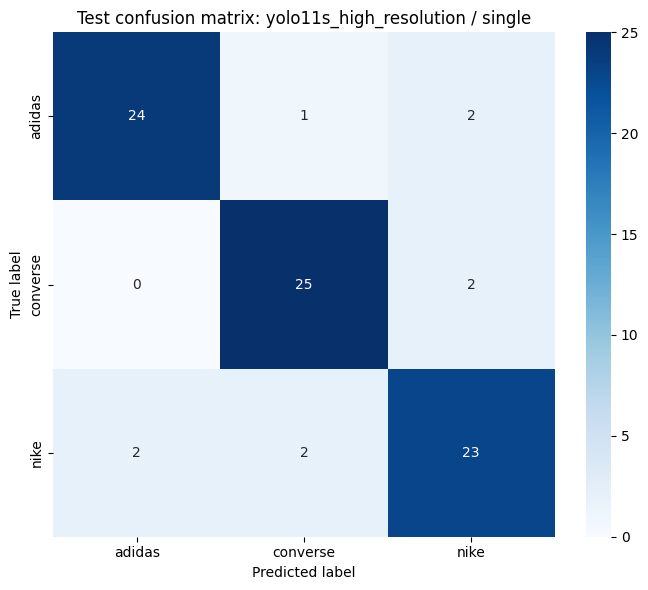

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
YOLO11s-cls summary (fused): 47 layers, 5,437,971 parameters, 0 gradients, 3.0 GFLOPs

PyTorch: starting from 'C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust\best_model.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 3) (10.5 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success  1.7s, saved as 'C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust\best_model.onnx' (20.8 MB)

Export complete (1.8s)
Results saved to C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust\best_model.onnx
Predict:         yolo predict task=classify model=C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust\best_model.onnx imgsz=320 
Validate:        yolo val task=classify model=C:\my-project\shoe-brand-classifier\modeling\runs\training\yolo11s_robust\best_

In [8]:
model_comparison.to_csv(OUTPUT_ROOT / "model_comparison.csv", index=False)
for prediction_name, predictions in validation_predictions.items():
    predictions.to_csv(OUTPUT_ROOT / f"validation_predictions_{prediction_name}.csv", index=False)
test_predictions.to_csv(OUTPUT_ROOT / "test_predictions.csv", index=False)
classification_report_frame.to_csv(OUTPUT_ROOT / "classification_report.csv")
pd.DataFrame(confusion_counts, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES).to_csv(OUTPUT_ROOT / "confusion_matrix.csv")
with (OUTPUT_ROOT / "metrics_summary.json").open("w", encoding="utf-8") as metrics_file:
    json.dump({**test_metrics, "acceptance": acceptance, "accepted_for_production": accepted_for_production}, metrics_file, indent=2)
manifest = {"selected_checkpoint": str(selected_checkpoint), "selection_metric": "validation_macro_f1", "seed": SEED, "device": str(DEVICE), "ultralytics_version": ultralytics_version, "pytorch_version": torch.__version__}
with (OUTPUT_ROOT / "experiment_manifest.json").open("w", encoding="utf-8") as manifest_file:
    json.dump(manifest, manifest_file, indent=2)

figure, axis = plt.subplots(figsize=(7, 6))
sns.heatmap(confusion_counts, annot=True, fmt="d", cmap="Blues", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axis)
axis.set_xlabel("Predicted label")
axis.set_ylabel("True label")
axis.set_title(f"Test confusion matrix: {selected_model_name} / {selected_strategy}")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

if accepted_for_production:
    best_model_path = OUTPUT_ROOT / "best_model.pt"
    shutil.copy2(selected_checkpoint, best_model_path)
    onnx_path = None
    if EXPORT_ONNX:
        onnx_path = Path(YOLO(str(best_model_path)).export(format="onnx", imgsz=selected_image_size, batch=1, dynamic=False, simplify=True, device=DEVICE))
    package_name = f"{datetime.now():%Y-%m-%d_%H-%M-%S}_yolo11s-robust-best"
    package_root = PROJECT_ROOT / "model" / package_name
    package_root.mkdir(parents=True, exist_ok=False)
    packaged_pt = package_root / "model.pt"
    shutil.copy2(best_model_path, packaged_pt)
    packaged_onnx = None
    if onnx_path is not None:
        packaged_onnx = package_root / "model.onnx"
        shutil.copy2(onnx_path, packaged_onnx)
    package_metadata = {"model": selected_model_name, "strategy": selected_strategy, "image_size": selected_image_size, "classes": EXPECTED_CLASSES, "metrics": test_metrics, "acceptance": acceptance, "pt_sha256": hashlib.sha256(packaged_pt.read_bytes()).hexdigest().upper(), "onnx_sha256": hashlib.sha256(packaged_onnx.read_bytes()).hexdigest().upper() if packaged_onnx else None}
    (package_root / "metadata.json").write_text(json.dumps(package_metadata, indent=2), encoding="utf-8")
    print(f"New production package: {package_root}")
else:
    print("Candidate did not pass every acceptance criterion. The existing production model remains active.")